# Citibike January demand reproduction

This was a collaborative group project, and I actively contributed to every stage of its development.

This notebook runs the portable workflow. Original notebooks and their historical outputs are preserved separately.

In [1]:
from pathlib import Path
import os, runpy, sys, json
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
os.chdir(root)
data_path = Path(os.environ.get('CITIBIKE_ZIP', 'data/raw/202301-citibike-tripdata.zip'))
if not data_path.exists():
    raise FileNotFoundError('Run python scripts/download_data.py first, or set CITIBIKE_ZIP.')
sys.argv = ['scripts/reproduce.py', '--data', str(data_path)]
runpy.run_path('scripts/reproduce.py', run_name='__main__')

{
  "archive_sha256": "7a3a25d977e72f46307d52cab8a450ceb0f496533c6e9cabfd4bc3c4655c8849",
  "csv_members": [
    "202301-citibike-tripdata_1.csv",
    "202301-citibike-tripdata_2.csv"
  ],
  "raw_trips": 1795412,
  "cleaned_trips": 1790985,
  "cleaning_retention": 0.9975342706855028,
  "observed_station_ids": 1763,
  "city_january_departures": 1790801,
  "city_january_arrivals": 1790985,
  "arrivals_after_january": 0,
  "busiest_stations_evaluated": 20,
  "forecast_summary": [
    {
      "model": "Hour-of-week mean",
      "mae": 3.7806795634920634,
      "rmse": 5.555608188163942
    },
    {
      "model": "Previous-day naive",
      "mae": 4.430357142857143,
      "rmse": 6.574220552975741
    }
  ],
  "python": "3.12.14",
  "scope": "Full January 2023 archive, portable pandas flow aggregation and demand baselines. Not a rerun of a complete annual Databricks/VRP system; stages 2-5 in the supplied DBC files are empty."
}


{'__name__': '__main__',
 '__doc__': 'Portable January 2023 flow analysis and chronological forecasting baseline.\n\nRun with a real monthly trip ZIP. No inventory capacities or simulated benefits\nare inferred from trip records alone. Raw archives stay outside the repository.\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'scripts/reproduce.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='bui

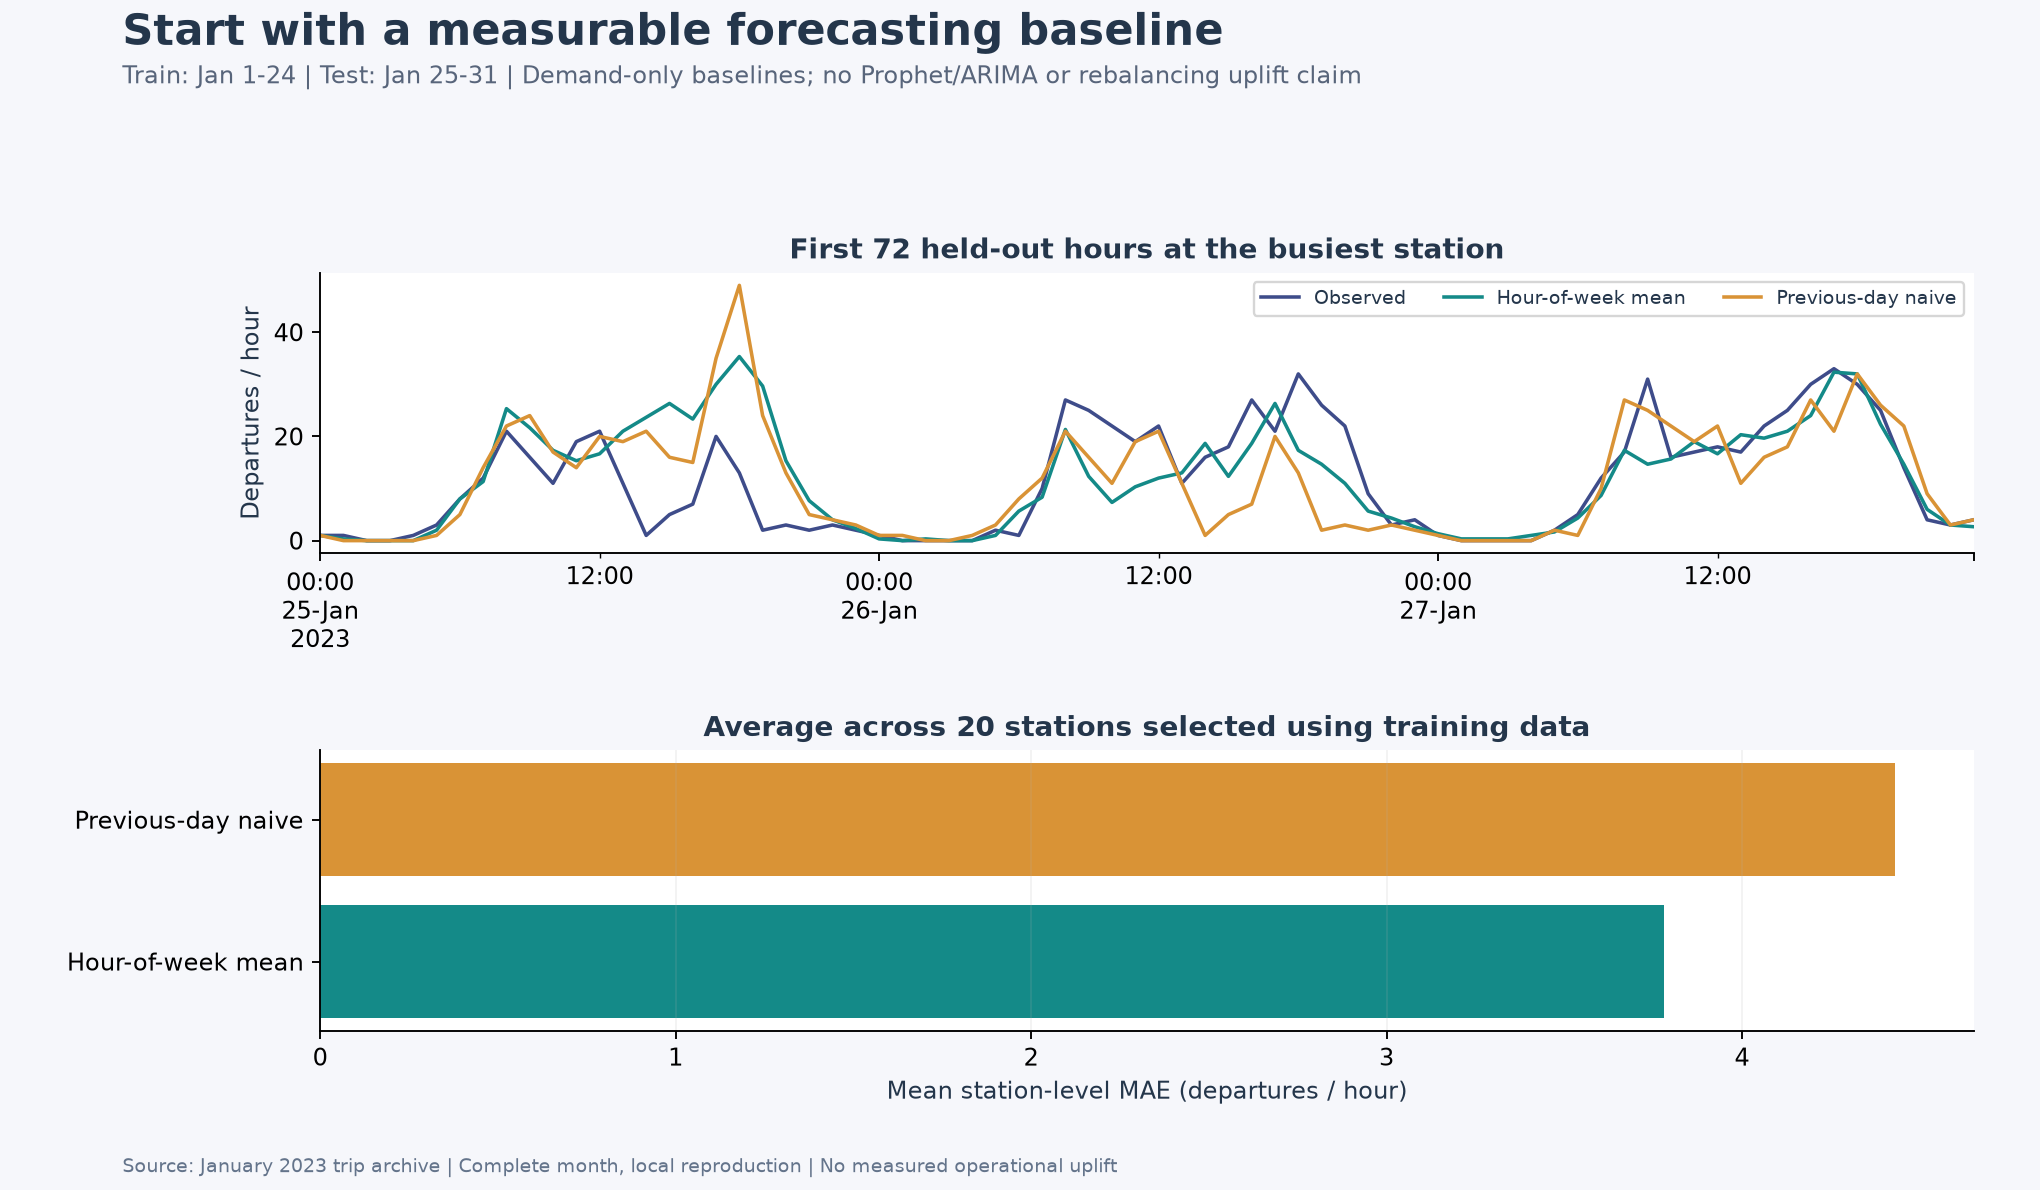

{'archive_sha256': '7a3a25d977e72f46307d52cab8a450ceb0f496533c6e9cabfd4bc3c4655c8849',
 'csv_members': ['202301-citibike-tripdata_1.csv',
  '202301-citibike-tripdata_2.csv'],
 'raw_trips': 1795412,
 'cleaned_trips': 1790985,
 'cleaning_retention': 0.9975342706855028,
 'observed_station_ids': 1763,
 'city_january_departures': 1790801,
 'city_january_arrivals': 1790985,
 'arrivals_after_january': 0,
 'busiest_stations_evaluated': 20,
 'forecast_summary': [{'model': 'Hour-of-week mean',
   'mae': 3.7806795634920634,
   'rmse': 5.555608188163942},
  {'model': 'Previous-day naive',
   'mae': 4.430357142857143,
   'rmse': 6.574220552975741}],
 'python': '3.12.14',
 'scope': 'Full January 2023 archive, portable pandas flow aggregation and demand baselines. Not a rerun of a complete annual Databricks/VRP system; stages 2-5 in the supplied DBC files are empty.'}

In [2]:
from IPython.display import Image, display
display(Image(filename='results/refreshed/forecast_baselines.png'))
summary = json.loads(Path('results/refreshed/run_summary.json').read_text())
summary